<span style="font-family:monospace;letter-spacing:.14em;color:#857259">BANA · MODULE 2 · EXPLORING AND VISUALISING DATA</span>

# Session 3: Missing values, outliers and categories

**Dataset:** EV purchase intention (Kaggle Playground Series S6E9, a *synthetic* dataset). You work with a 10,000-row seeded sample, `ev_m2_sample.csv`.
**Time:** 60 minutes. **Course outcomes:** CO2 (and CO3 for Session 5).

| Block | Min | What you do |
|---|---|---|
| Hook | 5 | Is a spike at 30,000 real income? |
| Concept | 10 | Why values go missing; the IQR rule (instructor) |
| Guided lab | 30 | Blanks, outliers, floors, category rates |
| Team task | 10 | Three keep / fix / explain decisions |
| Exit ticket | 5 | Three quick checks |

**By the end of this session you can:**
- find blanks and test whether they are random
- compare three ways to handle blanks
- find outliers with the IQR rule and decide keep / fix / explain
- read a category rate and its group size

**New commands this session (max 5):** `boxplot`, `quantile()`, a boolean filter `df[df[col] > x]`, bar chart of a rate, `pd.crosstab()`

**AI-use (AMBER protocol).** You may use an AI tool to look up *syntax*. The reasoning and interpretation must be your own: you will defend them in the viva.

## Facilitator notes: Session 3
**Question for the room:** *Which odd or missing values do we keep, fix or explain?*

**Plant (read before class).** The blanks in `ev_m2_sample.csv` were **injected by the instructor** (Kaggle's file has none): income is blank for **10.2% of Rural, 4.9% of Suburban, 2.4% of Urban** rows (so missingness depends on city: *missing at random*, MAR); commute and environmental concern are blank at about 2% each, completely at random (MCAR). The untouched truth is `ev_m2_sample_clean.csv`; keep it for the reveal in Part C.

**Run of show**
1. **Hook (5):** put the income histogram on screen. Ask: is 30,000 the real income of 8.8% of people, or a floor?
2. **Concept (10):** MCAR vs MAR vs not-at-random (Rubin, 1976; Little & Rubin, 2019). IQR fences (Tukey, 1977). Keep / fix / explain.
3. **Lab (30):** Parts B to E.
4. **Team task (10):** a three-row decision log.

**Honest result to share.** In this file, dropping or imputing income changes the mean income by well under 1%, because income does not depend on city. The *lesson* is the checking routine, not a dramatic change. Missingness *does* shift the city mix slightly when rows are dropped.

**Small groups.** Rural with no home charging has only **58** rows; High range anxiety only **24**. Both are shown in Part E so students see why small groups make shaky percentages.

In [1]:
# -- Setup: run once ------------------------------------------------------
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
warnings.filterwarnings("ignore")

# House style: Nikhil D Jonathan design system (sand ground, terracotta / lagoon / ochre data colours)
C = {"lagoon": "#25707B", "terracotta": "#B5562F", "ochre": "#E0A231", "moss": "#3F6F4B",
     "earth": "#665643", "ink": "#221B15", "sand": "#F8F3EA", "card": "#FFFDF9", "line": "#E3D6C1"}
sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": C["sand"], "axes.facecolor": C["card"], "axes.edgecolor": "#CDBCA3",
    "grid.color": C["line"], "text.color": C["ink"], "axes.labelcolor": C["ink"],
    "xtick.color": "#4A3E31", "ytick.color": "#4A3E31", "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 100, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left"})
PCT = PercentFormatter(1, decimals=0)                              # axis labels as percentages
SEQ = sns.light_palette(C["terracotta"], as_cmap=True)   # one-hue sequential map for heatmaps

# -- Load the data (Colab: upload ev_m2_sample.csv to the Files pane, or run the upload below)
FILE = "ev_m2_sample.csv"
if not os.path.exists(FILE):
    try:
        from google.colab import files
        print("Choose ev_m2_sample.csv"); files.upload()
    except ImportError:
        raise FileNotFoundError("Put ev_m2_sample.csv in the same folder as this notebook.")
raw = pd.read_csv(FILE)
df = raw.copy()
print("Loaded", df.shape[0], "rows x", df.shape[1], "columns")

Loaded 10000 rows x 15 columns


## Part A. Hook (5 min)
Run the histogram of income again and look at the left edge.

In [2]:
def add_derived(d):
    """The four derived columns built in Session 1 (pre-written so every notebook stands alone)."""
    d = d.copy()
    d["buy"] = (d["Will_Buy_EV"] == "Yes").astype(int)
    d["age_band"] = pd.cut(d["Age"], bins=[24, 34, 44, 54, 69], labels=["25-34", "35-44", "45-54", "55-69"])
    d["income_band"] = pd.qcut(d["Annual_Income_USD"], 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
    d["charger_total"] = d["Charging_Stations_Near_Home"] + d["Charging_Stations_Near_Work"]
    return d

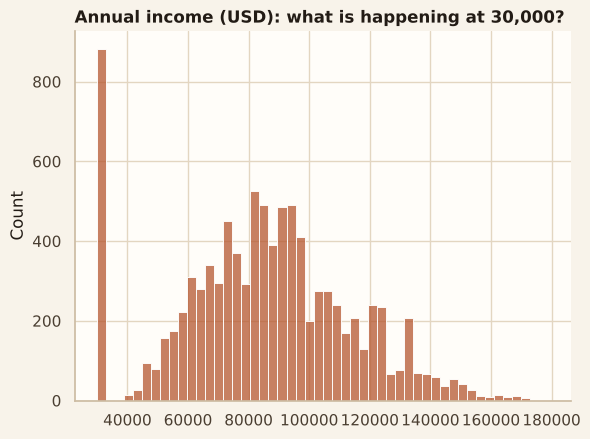

In [3]:
df = raw.copy()
sns.histplot(df["Annual_Income_USD"], bins=50, color=C["terracotta"])
plt.title("Annual income (USD): what is happening at 30,000?")
plt.xlabel("");

**Discuss in pairs (1 min):** is this person's income *really* exactly 30,000? What would a manager do with a segment that may be hidden by a floor?

## Part B. Blanks: how many, and are they random? (10 min)

In [4]:
blanks = df.isna().sum()
pd.DataFrame({"blanks": blanks, "percent": (100 * blanks / len(df)).round(1)}).query("blanks > 0")

,blanks,percent
Annual_Income_USD,488,4.9
Daily_Commute_km,165,1.6
Environmental_Concern_Level,194,1.9


In [5]:
# Are blank incomes spread evenly across city types?
df["income_missing"] = df["Annual_Income_USD"].isna()
df.groupby("City_Type")["income_missing"].mean().round(3)

City_Type
Rural       0.102
Suburban    0.049
Urban       0.024
Name: income_missing, dtype: float64

**YOUR ANSWER:** Are the blanks random across city types? What does your answer mean for *dropping* those rows?

> _write here_

**Expected:** no. Rural 10.2%, Suburban 4.9%, Urban 2.4%. Dropping blank-income rows removes proportionally more rural people, so the city mix changes.

**Three ways to handle blank income.** Compare them side by side.

In [6]:
options = {
    "A. drop rows with blank income": df.dropna(subset=["Annual_Income_USD"]),
    "B. fill with overall median": df.assign(Annual_Income_USD=df["Annual_Income_USD"].fillna(df["Annual_Income_USD"].median())),
    "C. fill with median of the same city type": df.assign(
        Annual_Income_USD=df["Annual_Income_USD"].fillna(df.groupby("City_Type")["Annual_Income_USD"].transform("median"))),
}
rows = []
for name, d in options.items():
    rows.append({"option": name, "rows kept": len(d), "mean income": round(d["Annual_Income_USD"].mean()),
                 "rural share": round((d["City_Type"] == "Rural").mean(), 3),
                 "yes rate": round((d["Will_Buy_EV"] == "Yes").mean(), 3)})
pd.DataFrame(rows)

,option,rows kept,mean income,rural share,yes rate
0,A. drop rows with blank income,9512,84807,0.181,0.182
1,B. fill with overall median,10000,84808,0.191,0.182
2,C. fill with median of the same city type,10000,84805,0.191,0.182


**YOUR ANSWER:** Which option would you choose, and why? What does each option assume?

> _write here_

In [7]:
# Does being blank relate to the outcome?
df.groupby("income_missing")["Will_Buy_EV"].apply(lambda s: (s == "Yes").mean()).round(3)

income_missing
False    0.182
True     0.184
Name: Will_Buy_EV, dtype: float64

In [8]:
# INSTRUCTOR REVEAL: compare against the untouched file
truth = pd.read_csv("ev_m2_sample_clean.csv")
print("True mean income:", round(truth["Annual_Income_USD"].mean()))
for name, d in options.items():
    print(f"{name:45s} -> {d['Annual_Income_USD'].mean():,.0f}")
mask = df["Annual_Income_USD"].isna()
for name, fill in [("overall median", df["Annual_Income_USD"].median()),
                   ("city median", df.groupby("City_Type")["Annual_Income_USD"].transform("median")[mask])]:
    err = (truth.loc[mask, "Annual_Income_USD"] - fill).abs().mean()
    print(f"Average error when filling blanks with {name}: {err:,.0f}")

True mean income: 84781
A. drop rows with blank income                -> 84,807
B. fill with overall median                   -> 84,808
C. fill with median of the same city type     -> 84,805
Average error when filling blanks with overall median: 22,742
Average error when filling blanks with city median: 22,733


**Expected:** all three means land within about 1% of the true mean income because income barely differs by city. Individual-level error is large (about 23,000 per blank) whichever fill is used, and the city median is no better than the overall median here (22,733 vs 22,742), so imputed values are fine for group summaries and weak for individual conclusions. **Environmental concern** (about 2% blank, MCAR) is the strongest predictor of buying: we *drop* those 194 rows rather than fill them with a middle value that would blur the signal.

## Part C. Outliers with the IQR rule (10 min)

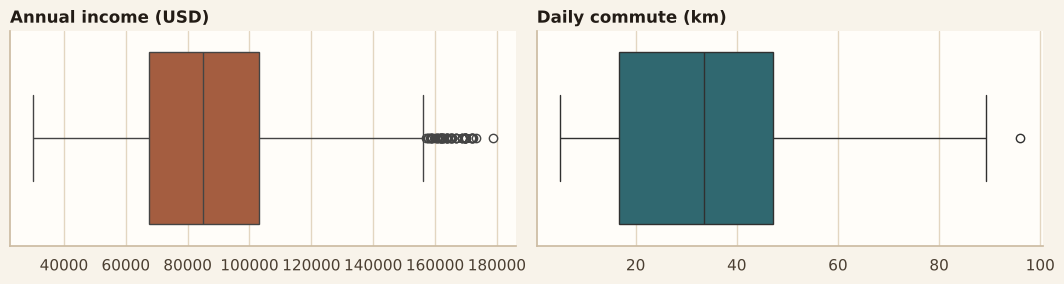

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
sns.boxplot(x=df["Annual_Income_USD"], color=C["terracotta"], ax=axes[0])
sns.boxplot(x=df["Daily_Commute_km"], color=C["lagoon"], ax=axes[1])
axes[0].set_title("Annual income (USD)"); axes[1].set_title("Daily commute (km)")
for a in axes: a.set_xlabel("")
plt.tight_layout()

In [10]:
def iqr_fences(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ["Annual_Income_USD", "Daily_Commute_km"]:
    low, high = iqr_fences(df[col])
    n_high = (df[col] > high).sum()
    print(f"{col}: fences {low:,.0f} to {high:,.0f}; rows above the upper fence: {n_high}")

Annual_Income_USD: fences 14,095 to 156,278; rows above the upper fence: 53
Daily_Commute_km: fences -29 to 93; rows above the upper fence: 1


In [11]:
# Look at the high-income rows themselves (boolean filter)
low, high = iqr_fences(df["Annual_Income_USD"])
rich = df[df["Annual_Income_USD"] > high]
print(len(rich), "rows;", f"Yes rate among them: {(rich['Will_Buy_EV'] == 'Yes').mean():.0%}")
rich[["Age", "Annual_Income_USD", "City_Type", "Environmental_Concern_Level", "Subsidy_Available", "Will_Buy_EV"]].head(8)

53 rows; Yes rate among them: 42%


,Age,Annual_Income_USD,City_Type,Environmental_Concern_Level,Subsidy_Available,Will_Buy_EV
94,39,162643.0,Urban,4.0,Yes,Yes
156,55,163958.0,Urban,1.0,No,No
476,52,169533.0,Urban,3.0,No,No
498,35,171467.0,Urban,4.0,Yes,Yes
527,28,160772.0,Urban,3.0,Yes,No
647,34,158926.0,Urban,5.0,Yes,Yes
652,60,159939.0,Urban,4.0,No,No
710,40,165093.0,Urban,2.0,Yes,Yes


**Expected:** income upper fence ≈ 156,278, with 53 rows above (about 0.5%); commute upper fence ≈ 93 km, with 1 row(s). The high earners are not errors: they are the best prospects. **Keep.** The *floor* spike (income = 30,000, commute = 5 km) is not an IQR outlier at all: it sits inside the fences. This is why you must also *look* at the histogram: a rule finds extremes, only your eyes find a pile-up.

## Part D. Floors: flag, do not delete (3 min)

In [12]:
df["income_at_floor"] = df["Annual_Income_USD"] == 30000
df["commute_at_floor"] = df["Daily_Commute_km"] == 5
print(df.groupby("income_at_floor")["Will_Buy_EV"].apply(lambda s: (s == "Yes").mean()).round(3))
print(df[["income_at_floor", "commute_at_floor"]].mean().round(3))

income_at_floor
False    0.196
True     0.040
Name: Will_Buy_EV, dtype: float64
income_at_floor     0.088
commute_at_floor    0.217
dtype: float64


**YOUR ANSWER:** What does the Yes rate for 'income at floor' tell you? What would you tell the business about customers *below* 30,000, who we cannot see in this data?

> _write here_

## Part E. Categories: rates AND group sizes (7 min)

In [13]:
pd.crosstab(df["City_Type"], df["Will_Buy_EV"], normalize="index").round(3)

Will_Buy_EV,No,Yes
City_Type,,
Rural,0.784,0.216
Suburban,0.815,0.185
Urban,0.836,0.164


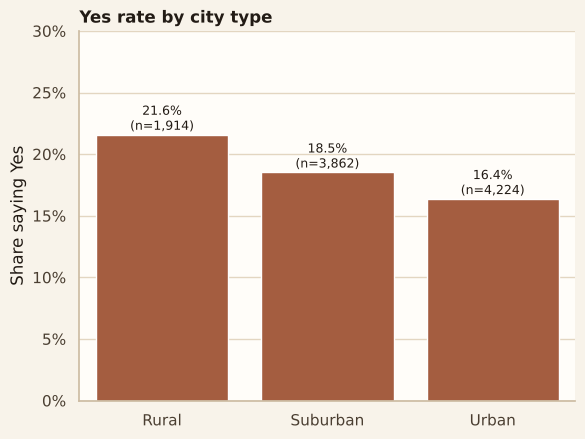

In [14]:
rate = df.groupby("City_Type")["Will_Buy_EV"].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
n = df["City_Type"].value_counts()
ax = sns.barplot(x=rate.index, y=rate.values, color=C["terracotta"])
for i, city in enumerate(rate.index):
    ax.text(i, rate[city] + 0.004, f"{rate[city]:.1%}\n(n={n[city]:,})", ha="center", fontsize=9)
ax.set_ylim(0, 0.30); ax.set_ylabel("Share saying Yes"); ax.yaxis.set_major_formatter(PCT); ax.set_xlabel("")
ax.set_title("Yes rate by city type");

In [15]:
# Small groups: how many rows sit behind each percentage?
print(df["Range_Anxiety_Level"].value_counts())
print()
print(df.groupby(["City_Type", "Home_Charging_Possible"]).size().unstack())

Range_Anxiety_Level
Low       9020
Medium     956
High        24
Name: count, dtype: int64

Home_Charging_Possible    No   Yes
City_Type                         
Rural                     58  1856
Suburban                 393  3469
Urban                   2559  1665


**YOUR ANSWER:** Which group is so small that a percentage from it would be unreliable? What would you do before quoting it?

> _write here_

**Expected:** `High` range anxiety has only 24 rows; Rural with no home charging has 58. Options: merge `Medium` and `High`, collect more data, or quote the count next to the rate.

## Team task: decision log (10 min)
Complete three rows. Each needs a **decision** (keep / fix / explain), a **reason**, and a **risk** if you are wrong.

| # | Issue | Decision | Reason | Risk if wrong |
|---|---|---|---|---|
| 1 | Blank incomes (about 5%) | | | |
| 2 | Pile-up at income 30,000 and commute 5 km | | | |
| 3 | High incomes above the fence | | | |

**Becomes:** the 'data-quality risks' section of your Project Charter in Session 5, and your data-preparation notes in Module 5.

In [16]:
# Apply the class decisions in one reusable function (used by Sessions 4 and 5)
def apply_s3_decisions(d):
    """Session 3 data-quality decisions, applied in one place (see your decision log)."""
    d = d.copy()
    d["income_was_missing"] = d["Annual_Income_USD"].isna()
    d["Annual_Income_USD"] = d["Annual_Income_USD"].fillna(d.groupby("City_Type")["Annual_Income_USD"].transform("median"))
    d["Daily_Commute_km"] = d["Daily_Commute_km"].fillna(d["Daily_Commute_km"].median())
    d = d.dropna(subset=["Environmental_Concern_Level"])      # strongest signal: do not blur it with a median
    d["income_at_floor"] = d["Annual_Income_USD"] == 30000
    d["commute_at_floor"] = d["Daily_Commute_km"] == 5
    return d

clean_df = add_derived(apply_s3_decisions(raw))
print(clean_df.shape, "| blanks left:", int(clean_df[["Annual_Income_USD", "Daily_Commute_km", "Environmental_Concern_Level"]].isna().sum().sum()))

(9806, 22) | blanks left: 0


## Exit ticket (5 min)
1. Blank incomes are more common in rural rows. Why does that make 'just drop them' risky?
2. The IQR rule did not flag the pile-up at 30,000. What did?
3. A group has a 40% Yes rate from 5 people. What do you say?

**Answers:** (1) dropping them changes the city mix and may bias results; (2) a histogram, i.e. looking; (3) the sample is too small to trust: report the count, collect more or combine groups.

**Viva prompt (AMBER):** "Show me one decision in your log and tell me what you would check if a manager challenged it."

### References (facilitator only)
Rubin, D. B. (1976). Inference and missing data. *Biometrika*, 63(3), 581-592.
Little, R. J. A., & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3rd ed.). Wiley.
Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.
Provost, F., & Fawcett, T. (2013). *Data Science for Business*. O'Reilly.